In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

2026-10-27 21:17:13.435516: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
# Generate polynomial data from -20 to +20
x = np.linspace(-20, 20, 5000).reshape(-1, 1)
y = 5*x**3 - 10*x**2 - 20*x + 10

# Normalize input and output to [-1, +1]
x_scaler = MinMaxScaler(feature_range=(-1,1))
y_scaler = MinMaxScaler(feature_range=(-1,1))

x_norm = x_scaler.fit_transform(x)
y_norm = y_scaler.fit_transform(y)

# 80% train, 10% validation, 10% test
x_train, x_other, y_train, y_other = train_test_split(
    x_norm, y_norm, test_size=0.20, random_state=42
)
x_val, x_test, y_val, y_test = train_test_split(
    x_other, y_other, test_size=0.50, random_state=42
)

print('Train:', len(x_train), ' Validation:', len(x_val), ' Test:', len(x_test))


Train: 4000  Validation: 500  Test: 500


In [3]:
# DNN: three hidden layers = 32, 64, 128
model = Sequential([
    Input(shape=(1,)),
    Dense(32, activation='relu'),
    Dense(64, activation='relu'),
    Dense(128, activation='relu'),
    Dense(1)
])

model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32)             │            64 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,625 (41.50 KB)

 Trainable params: 10,625 (41.50 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
# Train the DNN
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    verbose=1
)
print('Test loss and MAE:', model.evaluate(x_test, y_test, verbose=0))


Epoch 1/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.0221 - mae: 0.0985 - val_loss: 0.0031 - val_mae: 0.0381
Epoch 2/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0011 - mae: 0.0195 - val_loss: 3.0422e-04 - val_mae: 0.0103
Epoch 3/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.9108e-04 - mae: 0.0082 - val_loss: 1.6606e-04 - val_mae: 0.0097
Epoch 4/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 6.8948e-05 - mae: 0.0052 - val_loss: 3.4998e-05 - val_mae: 0.0037
Epoch 5/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 3.8720e-05 - mae: 0.0041 - val_loss: 3.0576e-05 - val_mae: 0.0042
Epoch 6/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 2.0803e-05 - mae: 0.0029 - val_loss: 1.3894e-05 - val_mae: 0.0025
Epoch 7/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.6379e-05 - mae: 0.0028 - val_loss: 7.0042e-06 - val_mae: 0.0014
Epoch 8/100
125/125 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 1.1708e-05 - mae: 0.0023 - val_loss: 4.6485e-06 - val_mae: 0.0

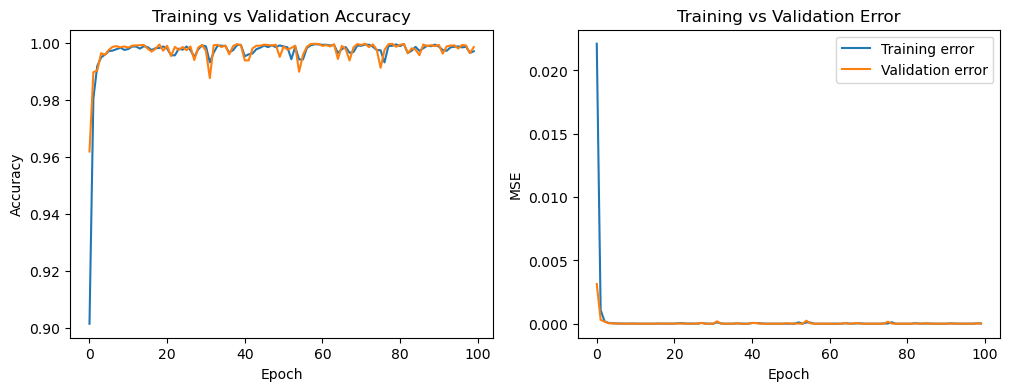

In [5]:
# Accuracy and error curves
accuracy = 1 - np.array(history.history['mae'])
val_accuracy = 1 - np.array(history.history['val_mae'])
error = history.history['loss']
val_error = history.history['val_loss']

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(accuracy, label='Training accuracy')
plt.plot(val_accuracy, label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.subplot(1, 2, 2)
plt.plot(error, label='Training error')
plt.plot(val_error, label='Validation error')
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.title('Training vs Validation Error')
plt.show()
